# NB3: Can stopping early save a network from wrong labels?

**COMP3620 CW3 · teaching notebook**

**Who is this for?** Anyone who has read our challenge statement, because it can be followed without our other notebooks and without reading the code.

**How long?** About 30 minutes of reading, and the code itself runs in under a minute.

**What do you need?** This notebook and the `results/` folder that comes with it; the pictures are downloaded automatically.

### The idea in a few lines

> A student learns from flashcards, but 30% of the answers on the cards are wrong.
>
> At first the student learns the real pattern, and only much later do they start to learn the wrong answers by heart, so if we stop the student at the right time, the wrong answers do little harm.
>
> **Our question:** does this still work when the wrong answers are not random, but always wrong *in the same way*?

### After this notebook you can explain

1. why stopping early helps when wrong labels are **random**;
2. why it helps **less** when wrong labels follow a **pattern**;
3. why we cannot say this is **always** true.

### How to use it

Run the cells from top to bottom. In two places, marked ✏️, we ask you to **guess before you look**, because a result is easier to remember once you have made a guess about it.

In [1]:
QUICK = True  # True: fast (small live demo + saved runs read from results/). False: also retrain the 15 full runs on this computer (about 8 minutes with a GPU).

## 0. Setup

The cell below imports the libraries and sets a few constants used in the rest of the notebook.

In [2]:
import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import json
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

DATA_DIR = Path("data")     # the pictures are downloaded here the first time
SAVE_FIGURES = False        # True: also save each figure as a PNG in figures/

NOISE_RATIO = 0.30      # 30% of the images of each digit get a wrong label
NUM_CLASSES = 10        # the digits 0-9
BATCH_SIZE = 128
HIDDEN = 512
SEEDS = [0, 1, 2]       # every experiment is repeated 3 times
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# The small live demo in section 3.
DEMO_N_TRAIN = 2000     # number of training images
DEMO_EPOCHS = 40        # number of passes through them
DEMO_LR = 1e-3          # learning rate
DEMO_SEED = 0

# Plain names and colours for the three kinds of labels.
NAMES = {"clean": "all labels correct", "random": "30% random mistakes", "systematic": "30% systematic mistakes"}
COLOURS = {"clean": "C0", "random": "C1", "systematic": "C3"}

print("running on:", DEVICE)


def save_fig(fig, name):
    if SAVE_FIGURES:
        Path("figures").mkdir(exist_ok=True)
        fig.savefig(Path("figures") / name, dpi=150)


def set_seed(seed):
    # Makes a run repeatable: same seed, same starting weights.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True, warn_only=True)

running on: cuda


## 1. Six words you need

| word | meaning |
|---|---|
| **label** | the answer that comes with a picture, for example "this is a 3" |
| **wrong label** | an answer that is not true: a picture of a 3 that says "7" |
| **epoch** | one round of training: the network sees every training picture once |
| **test score** | how many *new* pictures the network gets right, which is the number we care about |
| **learning by heart** | remembering single answers, without understanding the pattern |
| **early stopping** | instead of keeping the network from the last epoch, we keep it from the epoch where it did best on some spare pictures (the *validation set*) |

### What people already know

When some labels are wrong **at random**, a network learns in two steps (Arpit et al., 2017):

1. **First the pattern.** Most examples are correct, so it learns what a 3 looks like.
2. **Later the mistakes.** If we keep training, it also learns the wrong labels by heart, one by one, and then it gets worse on new pictures.

Early stopping keeps the network from the end of step 1: it knows the digits, but not yet the mistakes.

### Our question

> **Does early stopping still protect a network when the mistakes are systematic, not random?**

*Systematic* means always the same kind of mistake, and this happens in real life, for example when a tired person labels pictures and always mixes up the same two things.

### The pictures

We use MNIST: small pictures of handwritten digits, 0 to 9.

- **10,000 training pictures**, which the network learns from;
- **5,000 validation pictures**, which are only used to choose when to stop;
- **10,000 test pictures**, which give the final score and whose labels are **always correct**.

In [3]:
def load_split(dataset_class):
    # The same fixed split as in NB1 and NB2. dataset_class is datasets.MNIST or datasets.FashionMNIST.
    tf = transforms.ToTensor()
    train_full = dataset_class(DATA_DIR, train=True, download=True, transform=tf)
    test_full = dataset_class(DATA_DIR, train=False, download=True, transform=tf)

    def to_tensors(dataset):
        xs, ys = [], []
        for x, y in dataset:
            xs.append(x.reshape(-1))     # a 28 x 28 picture becomes a row of 784 numbers
            ys.append(int(y))
        return torch.stack(xs), torch.tensor(ys, dtype=torch.long)

    train_x, train_y = to_tensors(Subset(train_full, list(range(0, 10_000))))
    val_x, val_y = to_tensors(Subset(train_full, list(range(50_000, 55_000))))
    test_x, test_y = to_tensors(test_full)
    return train_x, train_y, val_x, val_y, test_x, test_y


mnist_data = load_split(datasets.MNIST)
train_x, train_y, val_x, val_y, test_x, test_y = mnist_data
print(f"training pictures: {len(train_x)} | validation pictures: {len(val_x)} | test pictures: {len(test_x)}")

training pictures: 10000 | validation pictures: 5000 | test pictures: 10000


## 2. Two ways for labels to be wrong

We add the mistakes ourselves, so we know exactly which labels are wrong.

For each digit, we pick 30% of its pictures and change their label. **We pick the same pictures in both cases**, so the only difference is the new label.

| | a picked picture of a 3 gets the label... | it is like... |
|---|---|---|
| **random mistakes** | any other digit, by chance: 0, 1, 2, 4, ..., 9 | a typo: wrong in a different way each time |
| **systematic mistakes** | always the next digit: **4** (and 4 → 5, ..., 9 → 0) | a bad habit: wrong in the same way every time |

The cell below creates both sets of labels and then shows eight pictures whose label was changed.

pictures with a changed label: 2999 of 10000 (30%)


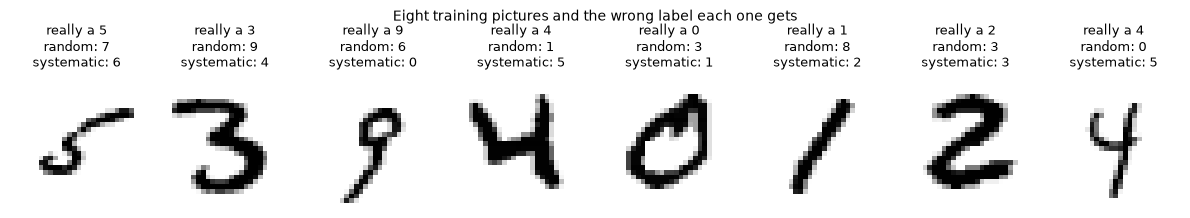

In [4]:
def make_mask(labels, ratio, rng):
    # Pick exactly `ratio` of the pictures of each digit.
    labels = np.asarray(labels)
    mask = np.zeros(len(labels), dtype=bool)
    for c in range(NUM_CLASSES):
        idx = np.flatnonzero(labels == c)
        n = int(round(len(idx) * ratio))
        if n > 0:
            mask[rng.choice(idx, size=n, replace=False)] = True
    return mask


def corrupt_labels(labels, noise_type, ratio, seed, split_id):
    # Returns (the labels the network will see, which pictures were picked). Same function as NB1 and NB2.
    labels = np.asarray(labels)
    rng = np.random.default_rng([seed, split_id])
    mask = make_mask(labels, ratio, rng)     # picked first, so it is the same for every kind of mistake
    corrupted = labels.copy()

    if noise_type == "random" and mask.any():
        true = labels[mask]
        wrong = rng.integers(0, NUM_CLASSES - 1, size=len(true))
        wrong = np.where(wrong >= true, wrong + 1, wrong)    # never the true digit: always wrong
        corrupted[mask] = wrong
    elif noise_type == "systematic" and mask.any():
        corrupted[mask] = (labels[mask] + 1) % NUM_CLASSES   # always the next digit
    elif noise_type == "clean":
        pass
    else:
        raise ValueError(f"unknown noise_type: {noise_type}")
    return corrupted, mask


y_true = train_y.numpy()
y_random, mask = corrupt_labels(y_true, "random", NOISE_RATIO, DEMO_SEED, split_id=0)
y_systematic, mask_s = corrupt_labels(y_true, "systematic", NOISE_RATIO, DEMO_SEED, split_id=0)

assert np.array_equal(mask, mask_s), "both kinds of mistake must change the same pictures"
print(f"pictures with a changed label: {mask.sum()} of {len(mask)} ({mask.mean():.0%})")

# Eight pictures whose label was changed.
fig, axes = plt.subplots(1, 8, figsize=(12, 2.3))
for ax, i in zip(axes, np.flatnonzero(mask)[:8]):
    ax.imshow(train_x[i].reshape(28, 28), cmap="gray_r")
    ax.set_title(f"really a {y_true[i]}\nrandom: {y_random[i]}\nsystematic: {y_systematic[i]}", fontsize=9)
    ax.axis("off")
fig.suptitle("Eight training pictures and the wrong label each one gets", fontsize=10)
fig.tight_layout()
plt.show()

### The most important picture

The chart below counts the labels on **all** training pictures of a 3, and the other nine digits give the same picture.

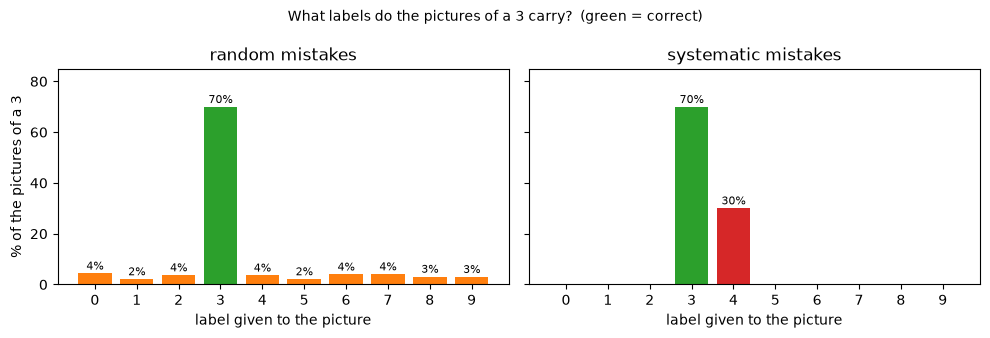

In [5]:
is_three = y_true == 3
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, (kind, given) in zip(axes, [("random", y_random), ("systematic", y_systematic)]):
    share = 100 * np.bincount(given[is_three], minlength=NUM_CLASSES) / is_three.sum()
    colours = ["C2" if d == 3 else COLOURS[kind] for d in range(NUM_CLASSES)]    # green = the correct label
    ax.bar(range(NUM_CLASSES), share, color=colours)
    for d in range(NUM_CLASSES):
        if share[d] > 0:
            ax.text(d, share[d] + 1.5, f"{share[d]:.0f}%", ha="center", fontsize=8)
    ax.set_xticks(range(NUM_CLASSES))
    ax.set_xlabel("label given to the picture")
    ax.set_ylim(0, 85)
    ax.set_title(f"{kind} mistakes")
axes[0].set_ylabel("% of the pictures of a 3")
fig.suptitle("What labels do the pictures of a 3 carry?  (green = correct)", fontsize=10)
fig.tight_layout()
save_fig(fig, "nb3_labels_of_a_three.png")
plt.show()

In both charts, 70% of the 3s still say "3", so the right answer is still the most common one.

- **Random (left):** the wrong 30% is spread over nine digits, about 3% each, so for every picture that wrongly says "7" there are about **21** that correctly say "3".
- **Systematic (right):** the wrong 30% all say "4", so for every **3** pictures that wrongly say "4" there are only **7** that correctly say "3".

> **Key point.** Random mistakes are many small voices that disagree, while systematic mistakes are one loud voice. The rest of the notebook is about how a network reacts to that difference.

## ✏️ Guess 1: what will the network say?

We train a small network two times: once with random mistakes, once with systematic mistakes. The network **never sees the true digits**, because it only gets the labels we give it.

Then we look at pictures that are really a **3** but have a wrong label, and we ask what the network calls them.

For **most** of these pictures, will the network say...

- **"true"**: a 3, which is the real digit even though the label says something else;
- **"given"**: the wrong label we gave it;
- **"other"**: something else?

| | early (after 5 epochs) | late (after 40 epochs) |
|---|---|---|
| trained with random mistakes | ? | ? |
| trained with systematic mistakes | ? | ? |

Type your four guesses into the next cell before you run it.

One more guess: **which network gets the better test score at its best moment?**

We follow 57 pictures of a 3 that carry a wrong label. Six of them:


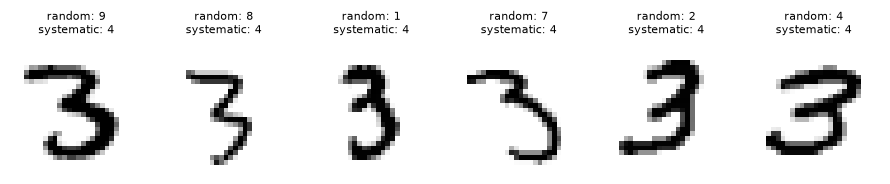

In [6]:
# Your guesses: replace each None with "true", "given" or "other".
my_answers = {
    ("random", 5): None,
    ("random", 40): None,
    ("systematic", 5): None,
    ("systematic", 40): None,
}
my_better_condition = None      # "random" or "systematic"

# The pictures we will follow: every 3 in the demo training set whose label was changed.
tracked = [i for i in range(DEMO_N_TRAIN) if mask[i] and y_true[i] == 3]
print(f"We follow {len(tracked)} pictures of a 3 that carry a wrong label. Six of them:")

fig, axes = plt.subplots(1, 6, figsize=(9, 2))
for ax, i in zip(axes, tracked[:6]):
    ax.imshow(train_x[i].reshape(28, 28), cmap="gray_r")
    ax.set_title(f"random: {y_random[i]}\nsystematic: {y_systematic[i]}", fontsize=8)
    ax.axis("off")
fig.tight_layout()
plt.show()

## 3. Watch it happen

The next cell defines the network and the training loop. In words, it does three things:

1. **Build a small network.** A picture goes in as 784 numbers (its pixels) and ten numbers come out, one for each digit, and the biggest one is the network's answer.
2. **Train.** In each epoch, the network sees every training picture with its **given** label, and changes itself a little to fit those labels better.
3. **Take notes after each epoch:**
   - what the network says for the pictures with a changed label;
   - its score on the validation pictures (early stopping uses this);
   - its score on the test pictures (the score we care about).

We leave out the usual tricks that slow down learning by heart (weight decay, dropout, data augmentation), which makes the effect easier to see.

The training code follows our NB1 and NB2 step by step; only the note-taking is shorter.

In [7]:
class MLP(nn.Module):
    def __init__(self, hidden=HIDDEN, num_classes=NUM_CLASSES):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, num_classes),
        )

    def forward(self, x):
        return self.net(x)


@torch.inference_mode()
def predict(model, x):
    # The digit the network chooses for each picture.
    model.eval()
    preds = [model(x[i:i + 512].to(DEVICE)).argmax(dim=1).cpu() for i in range(0, len(x), 512)]
    return torch.cat(preds).numpy()


def train_run(noise_type, lr, seed, n_train, epochs, data, track=(), verbose=False):
    # Train one network. Returns a dictionary of lists, one value per epoch.
    train_x, train_y, val_x, val_y, test_x, test_y = data
    set_seed(seed)

    # Labels. Training and validation labels contain mistakes; test labels never do.
    y_clean = train_y.numpy()
    y_given, sel = corrupt_labels(y_clean, noise_type, NOISE_RATIO, seed, split_id=0)
    v_given, _ = corrupt_labels(val_y.numpy(), noise_type, NOISE_RATIO, seed, split_id=1)
    t_true = test_y.numpy()

    x = train_x[:n_train]
    y_clean, y_given, sel = y_clean[:n_train], y_given[:n_train], sel[:n_train]

    g = torch.Generator().manual_seed(seed)           # fixes the order of the pictures
    loader = DataLoader(TensorDataset(x, torch.tensor(y_given, dtype=torch.long)),
                        batch_size=BATCH_SIZE, shuffle=True, generator=g)

    model = MLP().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()

    keys = ["train_acc_given", "selected_pred_true", "selected_pred_given",
            "val_acc_noisy", "test_acc", "test_err_next", "tracked_pred"]
    hist = {k: [] for k in keys}

    for epoch in range(1, epochs + 1):
        # --- learn: one pass through the training pictures, using the GIVEN labels only
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            loss_fn(model(xb), yb).backward()
            optimizer.step()

        # --- measure
        p_train, p_val, p_test = predict(model, x), predict(model, val_x), predict(model, test_x)
        wrong = p_test != t_true

        hist["train_acc_given"].append(float(np.mean(p_train == y_given)))
        # of the pictures whose label we changed: how many does it call by their TRUE digit?
        hist["selected_pred_true"].append(float(np.mean(p_train[sel] == y_clean[sel])))
        # ... and how many by the WRONG label we gave them?
        hist["selected_pred_given"].append(
            None if noise_type == "clean" else float(np.mean(p_train[sel] == y_given[sel])))
        # validation score, measured on labels that also contain mistakes (early stopping uses this)
        hist["val_acc_noisy"].append(float(np.mean(p_val == v_given)))
        # test score, measured on correct labels (the score we care about)
        hist["test_acc"].append(float(np.mean(p_test == t_true)))
        # of the test mistakes: how many are "said the next digit"?
        hist["test_err_next"].append(
            float(np.mean(p_test[wrong] == (t_true[wrong] + 1) % NUM_CLASSES)) if wrong.any() else None)
        hist["tracked_pred"].append([int(p_train[i]) for i in track])

        if verbose and (epoch % 20 == 0 or epoch == epochs):
            print(f"  epoch {epoch:3d}/{epochs} | validation {hist['val_acc_noisy'][-1]:.3f} | test {hist['test_acc'][-1]:.3f}")
    return hist


def stop_epoch(hist):
    # Early stopping: the epoch (counted from 0) with the best validation score.
    return int(np.argmax(hist["val_acc_noisy"]))

In [8]:
# Train the two demo networks. A few seconds each.
demo = {}
for kind in ["random", "systematic"]:
    t0 = time.perf_counter()
    demo[kind] = train_run(kind, DEMO_LR, DEMO_SEED, DEMO_N_TRAIN, DEMO_EPOCHS, mnist_data, track=tracked)
    print(f"trained with {kind} mistakes: {DEMO_EPOCHS} epochs on {DEMO_N_TRAIN} pictures, {time.perf_counter() - t0:.1f} s")

trained with random mistakes: 40 epochs on 2000 pictures, 2.3 s
trained with systematic mistakes: 40 epochs on 2000 pictures, 1.9 s


### ✅ Answer to Guess 1

The table shows what the network calls the wrongly labelled 3s, as training goes on.

In [9]:
given_labels = {"random": y_random[tracked], "systematic": y_systematic[tracked]}


def shares(kind, epoch):
    # Of the pictures we follow: share called "3" (true) / called by the wrong label (given) / anything else.
    pred = np.array(demo[kind]["tracked_pred"][epoch - 1])
    as_true = float(np.mean(pred == 3))
    as_given = float(np.mean(pred == given_labels[kind]))
    return {"true": as_true, "given": as_given, "other": 1 - as_true - as_given}


rows = []
for kind in ["random", "systematic"]:
    for e in [1, 3, 5, 10, 20, 40]:
        s = shares(kind, e)
        rows.append({"trained with": f"{kind} mistakes", "after epoch": e,
                     "says 3 (true)": f"{s['true']:.0%}",
                     "says the wrong label": f"{s['given']:.0%}",
                     "says something else": f"{s['other']:.0%}"})
print(pd.DataFrame(rows).to_string(index=False))

print("\nYour guesses:")
for (kind, e), guess in my_answers.items():
    s = shares(kind, e)
    actual = max(s, key=s.get)
    mark = "no guess entered" if guess is None else ("correct!" if guess == actual else "not this time")
    print(f"  {kind:10s} mistakes, after {e:2d} epochs: most common answer was '{actual}' ({s[actual]:.0%}). "
          f"You said: {guess} -> {mark}")

       trained with  after epoch says 3 (true) says the wrong label says something else
    random mistakes            1           74%                   4%                 23%
    random mistakes            3           81%                   7%                 12%
    random mistakes            5           88%                   5%                  7%
    random mistakes           10           47%                  44%                  9%
    random mistakes           20            5%                  95%                  0%
    random mistakes           40            0%                 100%                  0%
systematic mistakes            1           72%                   9%                 19%
systematic mistakes            3           46%                  28%                 26%
systematic mistakes            5           79%                  16%                  5%
systematic mistakes           10           39%                  61%                  0%
systematic mistakes           20

That was only a few dozen pictures of one digit, so the next figure shows the same thing for **every** training picture with a changed label, and also what happens to the test score.

- **Left and middle.** The solid line is how often the network says the **true** digit, and the dashed line is how often it says the **wrong label**.
- **Right.** The test score, with a dot where early stopping stops.

random     mistakes: early stopping keeps epoch 7. Test score there: 85%. After 40 epochs: 70%.
systematic mistakes: early stopping keeps epoch 8. Test score there: 75%. After 40 epochs: 67%.


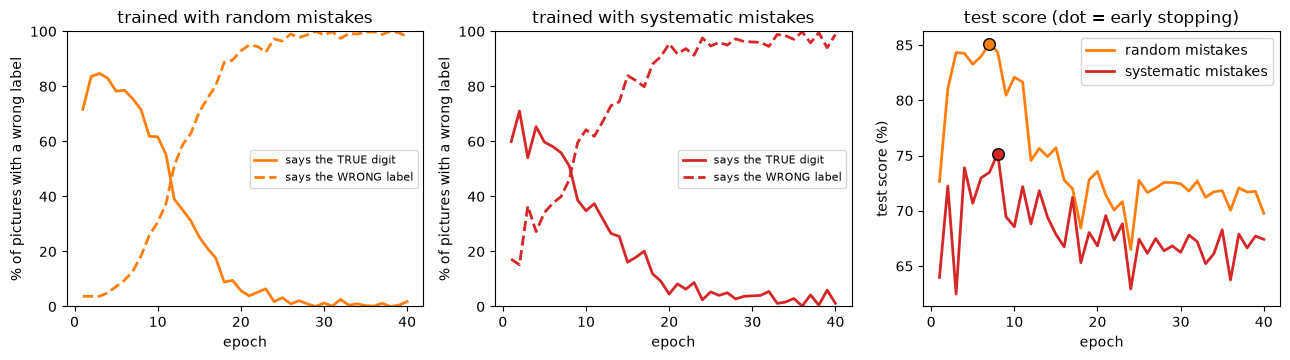


The better network at its early-stopping point was the one trained with random mistakes. You guessed: None


In [10]:
epochs_demo = np.arange(1, DEMO_EPOCHS + 1)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.7))

for ax, kind in zip(axes[:2], ["random", "systematic"]):
    h = demo[kind]
    ax.plot(epochs_demo, 100 * np.array(h["selected_pred_true"]), color=COLOURS[kind], lw=2, label="says the TRUE digit")
    ax.plot(epochs_demo, 100 * np.array(h["selected_pred_given"]), color=COLOURS[kind], lw=2, ls="--", label="says the WRONG label")
    ax.set_ylim(0, 100)
    ax.set_xlabel("epoch")
    ax.set_ylabel("% of pictures with a wrong label")
    ax.set_title(f"trained with {kind} mistakes")
    ax.legend(fontsize=8, loc="center right")

ax = axes[2]
for kind in ["random", "systematic"]:
    h = demo[kind]
    stop = stop_epoch(h)
    ax.plot(epochs_demo, 100 * np.array(h["test_acc"]), color=COLOURS[kind], lw=2, label=f"{kind} mistakes")
    ax.scatter([stop + 1], [100 * h["test_acc"][stop]], s=70, color=COLOURS[kind], edgecolor="k", zorder=3)
    print(f"{kind:10s} mistakes: early stopping keeps epoch {stop + 1}. Test score there: {h['test_acc'][stop]:.0%}. "
          f"After {DEMO_EPOCHS} epochs: {h['test_acc'][-1]:.0%}.")
ax.set_xlabel("epoch")
ax.set_ylabel("test score (%)")
ax.set_title("test score (dot = early stopping)")
ax.legend()

fig.tight_layout()
save_fig(fig, "nb3_demo.png")
plt.show()

best = max(demo, key=lambda k: demo[k]["test_acc"][stop_epoch(demo[k])])
print(f"\nThe better network at its early-stopping point was the one trained with {best} mistakes. You guessed: {my_better_condition}")

### What the demo shows

**Random mistakes (left picture).**
At the start, the solid line is high and the dashed line is near zero, so the network calls most wrongly labelled pictures by their **true** digit and is not fooled by the wrong labels. Later the two lines cross, because the network is now learning the wrong labels by heart, and at the same time the test score (right picture) goes down. **Early stopping stops before this happens**, which is the result people already know.

**Systematic mistakes (middle picture).**
Here the dashed line does **not** start near zero, because already in the first epochs the network calls some pictures by their wrong label. It is learning "a 3 is sometimes a 4" like a real rule, at the same time as it learns the digits.

**The test score (right picture).**
Both networks get worse when we train too long, and early stopping helps both, but the best moment of the systematic network is **lower**, because there is no epoch where it knows the digits and has not yet picked up the bad habit.

> **Key point.** Early stopping cuts training *between* "learned the pattern" and "learned the mistakes". With random mistakes there is a gap between the two, but with systematic mistakes they happen together.

*This demo is a single small run, so it illustrates the idea rather than proving it, and the evidence is in the next section.*

## 4. The real experiment

The demo was small so that it could run while you wait, while the real experiment is bigger and more careful.

| | demo | real experiment |
|---|---|---|
| training pictures | 2,000 | 10,000 |
| epochs | 40 | 200 |
| how many times we repeat it | 1 | 3 |
| kinds of labels | random, systematic | **all correct**, random, systematic |

Three things make the comparison fair:

- **One network gets only correct labels.** It shows how good the network can be, and whether long training is bad by itself.
- **We repeat everything 3 times.** Each repeat starts from different random weights and changes different pictures, and since two runs never give exactly the same number, a difference only counts if it is clearly bigger than the difference between repeats.
- **Each kind of labels gets its own best learning rate** (the learning rate is how big each training step is), because otherwise one kind could look worse only because its setting was bad.

### Where do the numbers come from?

These runs are too slow to repeat while you wait, so we use the runs from our NB1 and NB2, which are **saved in the `results/` folder** that comes with this notebook: 9 runs on MNIST (3 kinds of labels × 3 repeats) and 6 on Fashion-MNIST, each at the learning rate chosen in NB1 and NB2. These are exactly the runs NB2 reports, so every number below matches NB2.

We also trained the same 15 runs a second time, on another computer, with the `train_run` function you saw in the demo. That second copy is saved in `results/nb3_results.json`, and the box at the end of this section compares the two copies.

- `QUICK = True`: the notebook reads both saved copies.
- `QUICK = False`: the notebook trains the second copy again on your computer and saves it. This took about 8 minutes on our computer with a GPU, and it takes longer without one.

In [11]:
CONDITIONS = ["clean", "random", "systematic"]
FULL_N_TRAIN = 10_000
FULL_EPOCHS = 200

# Learning rate chosen for each kind of labels in NB1 and NB2. NB3 does not choose again.
SELECTED_LR = {"clean": 3e-3, "random": 1e-3, "systematic": 3e-3}


FASHION_LR = {"random": 3e-4, "systematic": 3e-3}    # the same choice, made for Fashion-MNIST in NB2

# For every run and every epoch we keep three numbers:
#   val_acc_noisy  validation score (what early stopping looks at)
#   test_acc       test score
#   test_err_next  share of the test mistakes that are "said the next class"
KEPT = ["val_acc_noisy", "test_acc", "test_err_next"]

RESULTS_DIR = Path("results")
RERUN_FILE = RESULTS_DIR / "nb3_results.json"     # our second copy of the same 15 runs


def nb2_run_file(dataset, condition, lr, seed):
    # Where NB1 and NB2 saved a run: MNIST in results/, Fashion-MNIST in results/sensitivity_fashion/.
    folder = RESULTS_DIR if dataset == "mnist" else RESULTS_DIR / "sensitivity_fashion"
    return folder / f"{condition}_lr{lr:g}_seed{seed}.json"


# 1. The runs that NB2 reports: 9 on MNIST and 6 on Fashion-MNIST. Read in both modes.
results = {"mnist": {}, "fashion": {}}
for dataset, lrs in [("mnist", SELECTED_LR), ("fashion", FASHION_LR)]:
    for condition, lr in lrs.items():
        results[dataset][condition] = []
        for seed in SEEDS:
            path = nb2_run_file(dataset, condition, lr, seed)
            if not path.exists():
                raise FileNotFoundError(f"{path.as_posix()} is missing. Keep the results/ folder from NB1 and NB2 "
                                        "next to this notebook.")
            metrics = json.loads(path.read_text())["metrics"]
            results[dataset][condition].append({k: metrics[k] for k in KEPT})
print("NB2's runs, read from results/:", sum(len(r) for r in results["mnist"].values()), "on MNIST and",
      sum(len(r) for r in results["fashion"].values()), "on Fashion-MNIST")

# 2. The second copy of the same 15 runs, trained with train_run: read it (QUICK = True) or train it again (QUICK = False).
t_start = time.perf_counter()
if QUICK:
    rerun = json.loads(RERUN_FILE.read_text())["runs"] if RERUN_FILE.exists() else None
    print("second copy:", f"read from {RERUN_FILE.as_posix()}" if rerun else "not found; set QUICK = False to train it")
else:
    rerun = {"mnist": {}, "fashion": {}}
    for condition in CONDITIONS:
        rerun["mnist"][condition] = []
        for seed in SEEDS:
            print(f"\n=== MNIST | {NAMES[condition]} | repeat {seed + 1} ===")
            rerun["mnist"][condition].append(
                train_run(condition, SELECTED_LR[condition], seed, FULL_N_TRAIN, FULL_EPOCHS, mnist_data, verbose=True))

    fashion_data = load_split(datasets.FashionMNIST)
    for condition in ["random", "systematic"]:
        rerun["fashion"][condition] = []
        for seed in SEEDS:
            print(f"\n=== Fashion-MNIST | {NAMES[condition]} | repeat {seed + 1} ===")
            rerun["fashion"][condition].append(
                train_run(condition, FASHION_LR[condition], seed, FULL_N_TRAIN, FULL_EPOCHS, fashion_data, verbose=True))

    # Save the three kept numbers of every run, so that QUICK = True can read them next time.
    saved = {
        "config": {"noise_ratio": NOISE_RATIO, "n_train": FULL_N_TRAIN, "epochs": FULL_EPOCHS, "seeds": SEEDS,
                   "lr": {"mnist": SELECTED_LR, "fashion": FASHION_LR}},
        "runs": {ds: {c: [{k: run[k] for k in KEPT} for run in runs] for c, runs in conds.items()}
                 for ds, conds in rerun.items()},
    }
    RERUN_FILE.parent.mkdir(exist_ok=True)
    RERUN_FILE.write_text(json.dumps(saved, separators=(",", ":")))
    print(f"\nsecond copy trained in {(time.perf_counter() - t_start) / 60:.1f} minutes; "
          f"saved to {RERUN_FILE.as_posix()}")

full = results["mnist"]          # {kind of labels: [3 runs]}, the runs NB2 reports
fashion = results["fashion"]

NB2's runs, read from results/: 9 on MNIST and 6 on Fashion-MNIST
second copy: read from results/nb3_results.json


### The scores

For each run we compare two choices:

- **stop early**: keep the epoch with the best validation score;
- **train to the end**: the average of the last 10 epochs.

In [12]:
def summarise(runs_by_condition):
    rows = []
    for condition, runs in runs_by_condition.items():
        for seed, h in zip(SEEDS, runs):
            stop = stop_epoch(h)
            rows.append({
                "condition": condition,
                "repeat": seed + 1,
                "stop_epoch": stop + 1,
                "acc_stop": h["test_acc"][stop],                    # test score if we stop early
                "acc_end": float(np.mean(h["test_acc"][-10:])),     # test score if we train to the end
                "acc_best": float(np.max(h["test_acc"])),           # best test score at any epoch
                "next_share": h["test_err_next"][stop],             # of the mistakes at the stop: share on the next class
            })
    return pd.DataFrame(rows)


per_run = summarise(full)

view = per_run.assign(
    labels=per_run["condition"].map(NAMES),
    stop_early=(100 * per_run["acc_stop"]).round(1),
    train_to_end=(100 * per_run["acc_end"]).round(1),
)[["labels", "repeat", "stop_epoch", "stop_early", "train_to_end"]]
print("Test score in %, one row per run:")
print(view.to_string(index=False))

avg = per_run.groupby("condition", sort=False)[["acc_stop", "acc_end"]].mean()
print("\nAverage of the 3 repeats:")
for c in CONDITIONS:
    a, b = avg.loc[c, "acc_stop"], avg.loc[c, "acc_end"]
    print(f"  {NAMES[c]:24s}: stop early {a:.1%} | train to the end {b:.1%} | stopping early adds {100 * (a - b):+.1f} points")

# How much of the damage does stopping early undo? The damage is measured against the network with all labels correct.
clean_end = avg.loc["clean", "acc_end"]
print("\nHow much of the damage does stopping early undo?")
for c in ["random", "systematic"]:
    a, b = avg.loc[c, "acc_stop"], avg.loc[c, "acc_end"]
    lost, won = 100 * (clean_end - b), 100 * (a - b)
    print(f"  {NAMES[c]:24s}: training to the end loses {lost:.1f} points; "
          f"stopping early wins back {won:.1f} of them ({won / lost:.0%})")

gap = 100 * (avg.loc["random", "acc_stop"] - avg.loc["systematic", "acc_stop"])
rnd = sorted((100 * per_run[per_run["condition"] == "random"]["acc_stop"]).round(1))
sys_ = sorted((100 * per_run[per_run["condition"] == "systematic"]["acc_stop"]).round(1))
print(f"\nStopping early, systematic mistakes cost {gap:.1f} points more than random mistakes.")
print(f"  the three random repeats:     {rnd}")
print(f"  the three systematic repeats: {sys_}")
print("  every systematic repeat is below every random repeat:", max(sys_) < min(rnd))

Test score in %, one row per run:
                 labels  repeat  stop_epoch  stop_early  train_to_end
     all labels correct       1          65        96.6          96.8
     all labels correct       2         149        96.5          96.7
     all labels correct       3          59        96.7          96.7
    30% random mistakes       1           5        93.1          77.3
    30% random mistakes       2           5        93.4          76.2
    30% random mistakes       3           5        93.8          78.6
30% systematic mistakes       1           3        90.8          71.3
30% systematic mistakes       2           5        89.4          69.8
30% systematic mistakes       3           5        90.0          72.4

Average of the 3 repeats:
  all labels correct      : stop early 96.6% | train to the end 96.7% | stopping early adds -0.1 points
  30% random mistakes     : stop early 93.4% | train to the end 77.4% | stopping early adds +16.0 points
  30% systematic mistakes : st

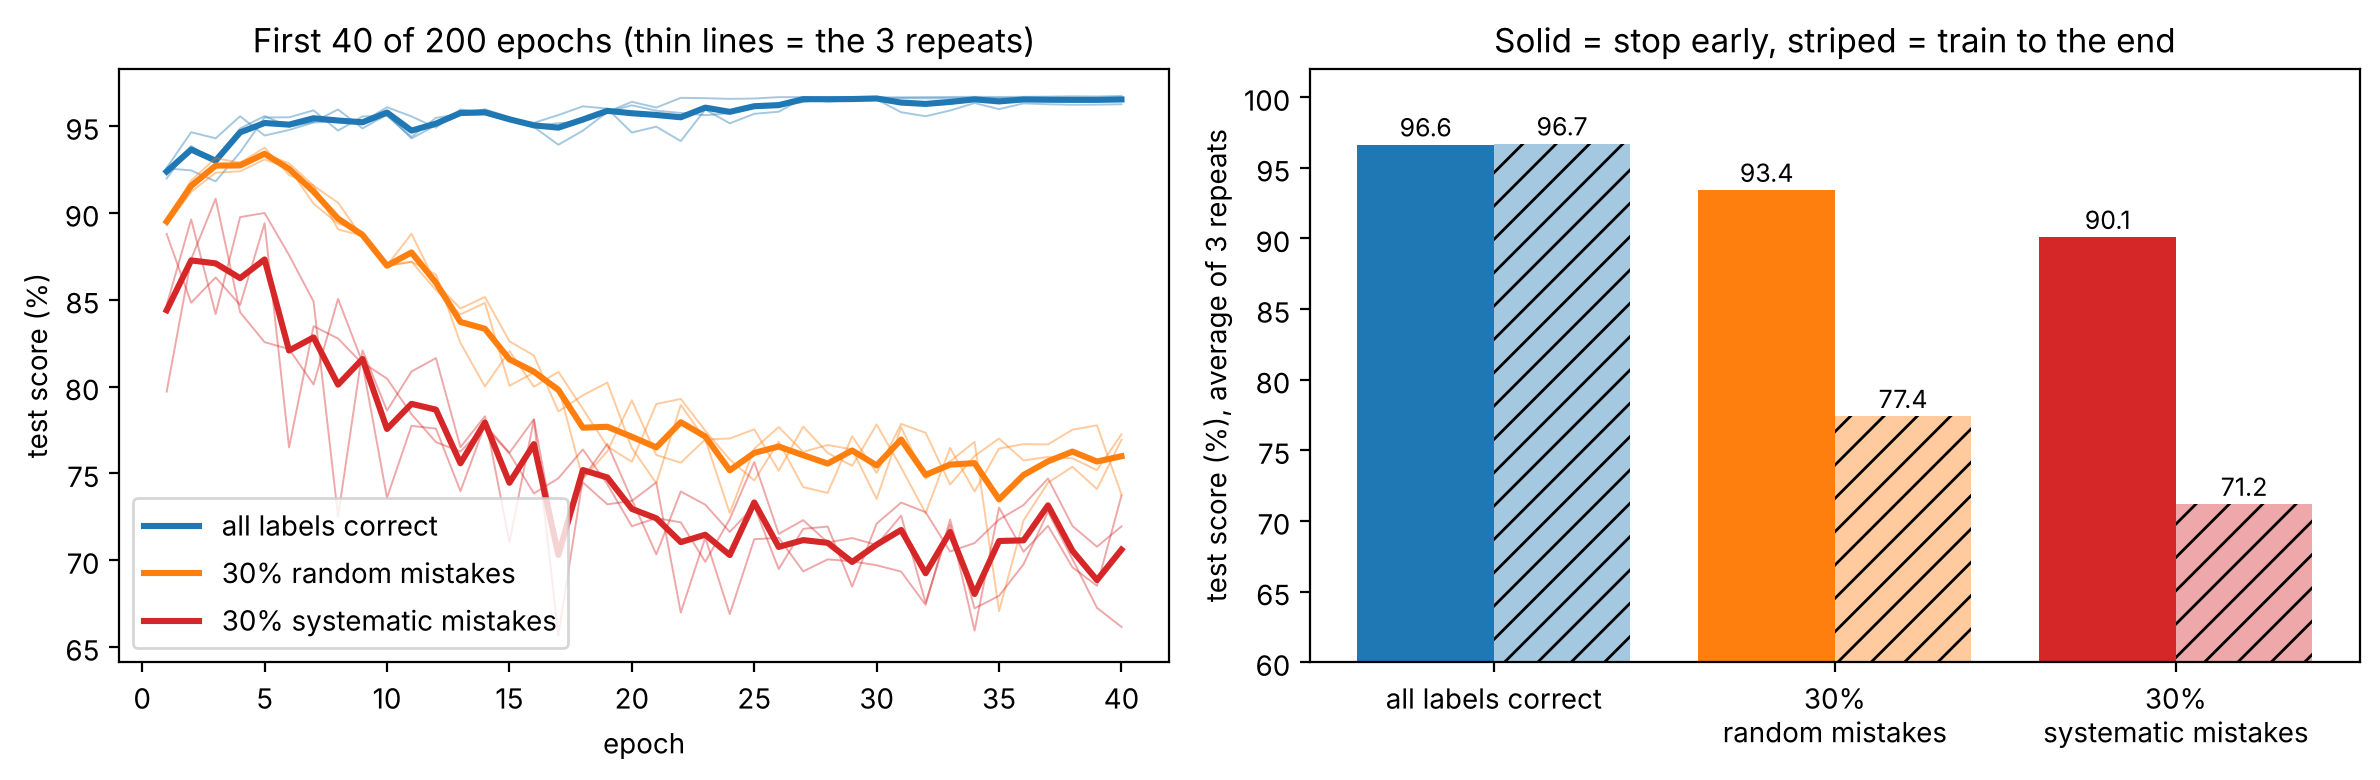

In [13]:
def mean_curve(runs, key):
    # Average of the three repeats, epoch by epoch.
    return np.array([[np.nan if v is None else v for v in h[key]] for h in runs], dtype=float).mean(axis=0)


SHOW = min(40, FULL_EPOCHS)      # the interesting part is at the start, so the left panel shows the first 40 epochs
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: test score over time.
ax = axes[0]
for c in CONDITIONS:
    for h in full[c]:
        ax.plot(np.arange(1, SHOW + 1), 100 * np.array(h["test_acc"][:SHOW]), color=COLOURS[c], lw=0.7, alpha=0.4)
    ax.plot(np.arange(1, SHOW + 1), 100 * mean_curve(full[c], "test_acc")[:SHOW], color=COLOURS[c], lw=2.2, label=NAMES[c])
ax.set_xlabel("epoch")
ax.set_ylabel("test score (%)")
ax.set_title(f"First {SHOW} of {FULL_EPOCHS} epochs (thin lines = the 3 repeats)")
ax.legend(loc="lower left")

# Right: stop early vs train to the end.
ax = axes[1]
pos = np.arange(len(CONDITIONS))
stop_vals = [100 * avg.loc[c, "acc_stop"] for c in CONDITIONS]
end_vals = [100 * avg.loc[c, "acc_end"] for c in CONDITIONS]
b1 = ax.bar(pos - 0.2, stop_vals, 0.4, color=[COLOURS[c] for c in CONDITIONS], label="stop early")
b2 = ax.bar(pos + 0.2, end_vals, 0.4, color=[COLOURS[c] for c in CONDITIONS], alpha=0.4, hatch="//", label="train to the end")
for bars in (b1, b2):
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.6, f"{bar.get_height():.1f}", ha="center", fontsize=9)
ax.set_xticks(pos)
ax.set_xticklabels([NAMES[c].replace("30% ", "30%\n") for c in CONDITIONS])
ax.set_ylim(60, 102)
ax.set_ylabel("test score (%), average of 3 repeats")
ax.set_title("Solid = stop early, striped = train to the end")

fig.tight_layout()
save_fig(fig, "nb3_full_results.png")
plt.show()

### How to read this

Reading the right-hand chart from left to right:

1. **All labels correct (blue).** The two bars are almost the same, so training for a long time is not bad by itself, and when the other bars drop, the wrong labels are the reason.
2. **Random mistakes (orange).** Training to the end loses a lot, but stopping early gets most of it back and ends only a few points under the blue bars. *This is the known result, and our runs reproduce it.*
3. **Systematic mistakes (red).** Stopping early still helps a lot, but the solid red bar is lower than the solid orange bar. The text printed above the chart tells you how big the gap is and whether every systematic repeat is under every random repeat, and if it is, the gap is unlikely to be just luck.

**Careful with "helps less".** Stopping early actually *adds more points* with systematic mistakes (about 19) than with random ones (about 16), as the numbers printed above the chart show. That is because training to the end does more damage with systematic mistakes, so there is more to win back. What is worse is where you end up: the solid red bar is about twice as far below the blue bars as the solid orange bar, and stopping early wins back about three quarters of the damage instead of more than four fifths.

> **Key point.** Same number of wrong labels, but with systematic mistakes early stopping ends lower and undoes a smaller share of the damage, even though it adds more points.

### What kind of mistakes does the network make?

There are two possible stories:

- **"The task is just harder"**, in which case the network's mistakes on test pictures should be spread over all digits;
- **"The network learned the bad habit"**, in which case its mistakes should often be "the next digit".

If mistakes were spread evenly, "the next digit" would be 1 mistake in 9, which is about 11%.

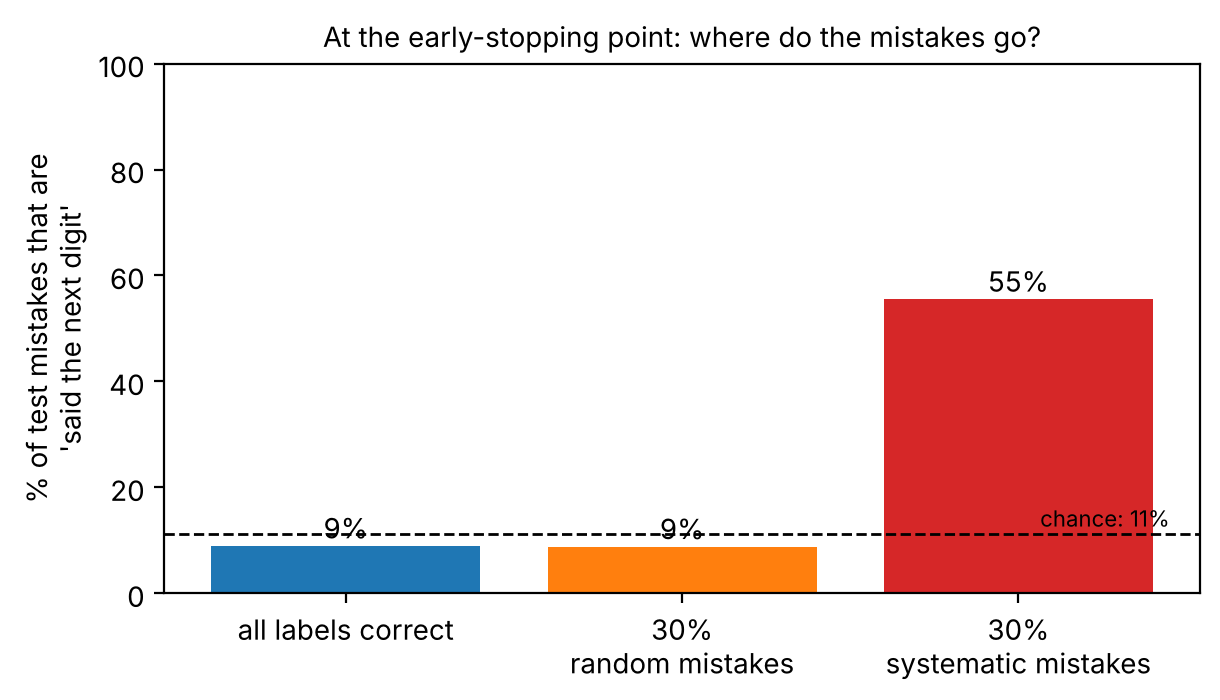

all labels correct      : 9% of its test mistakes are 'said the next digit'
30% random mistakes     : 9% of its test mistakes are 'said the next digit'
30% systematic mistakes : 55% of its test mistakes are 'said the next digit'


In [14]:
next_share = per_run.groupby("condition", sort=False)["next_share"].mean()

fig, ax = plt.subplots(figsize=(6.2, 3.6))
bars = ax.bar([NAMES[c].replace("30% ", "30%\n") for c in CONDITIONS], [100 * next_share[c] for c in CONDITIONS],
              color=[COLOURS[c] for c in CONDITIONS])
for bar in bars:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.5, f"{bar.get_height():.0f}%", ha="center")
ax.axhline(100 / 9, color="k", ls="--", lw=1)
ax.text(2.45, 100 / 9 + 1.5, "chance: 11%", ha="right", fontsize=8)
ax.set_ylim(0, 100)
ax.set_ylabel("% of test mistakes that are\n'said the next digit'")
ax.set_title("At the early-stopping point: where do the mistakes go?", fontsize=10)
fig.tight_layout()
save_fig(fig, "nb3_where_mistakes_go.png")
plt.show()

for c in CONDITIONS:
    print(f"{NAMES[c]:24s}: {next_share[c]:.0%} of its test mistakes are 'said the next digit'")

With correct labels or random mistakes, "next digit" mistakes are about as common as chance.

With systematic mistakes, more than **half** of all mistakes are "the next digit", which is several times more than chance and is already true at the moment we stop early.

> **Key point.** The network trained with systematic mistakes is not only a bit worse: it makes *the mistake it was taught* on pictures it has never seen, because it learned the bad habit as a rule.

### Same runs, another computer

Every number above comes from the runs NB2 reports. As said at the start of this section, we also trained the same 15 runs a second time on another computer, one with a GPU, using `train_run` from section 3. On the same computer, `train_run` and the training code in NB2 give exactly the same numbers. Between computers they do not: computers add up numbers in slightly different orders, and over 200 epochs these tiny differences grow. So the second copy works like one more set of repeats.

In [15]:
if rerun is None:
    print("No second copy found: set QUICK = False to train it on this computer.")
else:
    for name, ds in [("MNIST (digits)", "mnist"), ("Fashion-MNIST (clothes)", "fashion")]:
        print(name)
        box_rnd, box_sys = [], []
        for label, runs in [("NB2's runs ", results[ds]), ("second copy", rerun[ds])]:
            d_box = summarise(runs)
            r_acc = d_box[d_box["condition"] == "random"]["acc_stop"]
            s_acc = d_box[d_box["condition"] == "systematic"]["acc_stop"]
            box_rnd += list(r_acc)
            box_sys += list(s_acc)
            print(f"  {label}: stop early, random {r_acc.mean():.1%}, systematic {s_acc.mean():.1%} "
                  f"-> systematic costs {100 * (r_acc.mean() - s_acc.mean()):.1f} points more")
        print(f"  all {len(box_sys)} systematic runs below all {len(box_rnd)} random runs: {max(box_sys) < min(box_rnd)}\n")

MNIST (digits)
  NB2's runs : stop early, random 93.4%, systematic 90.1% -> systematic costs 3.3 points more
  second copy: stop early, random 93.4%, systematic 91.3% -> systematic costs 2.2 points more
  all 6 systematic runs below all 6 random runs: True

Fashion-MNIST (clothes)
  NB2's runs : stop early, random 83.7%, systematic 82.8% -> systematic costs 0.9 points more
  second copy: stop early, random 83.6%, systematic 82.2% -> systematic costs 1.4 points more
  all 6 systematic runs below all 6 random runs: False



On MNIST the second copy gives a smaller gap, 2.2 points instead of 3.3, but all six systematic runs are still below all six random runs. On Fashion-MNIST the gap stays small on both computers and the runs overlap. So the direction of the MNIST result is solid, while its exact size is less certain than three repeats on one computer suggest.

## ✏️ Guess 2: is this always true?

One experiment on one set of pictures is weak evidence, so we repeated it on different pictures: **Fashion-MNIST**, which has small pictures of clothes in 10 groups (T-shirt, trouser, pullover, ...).

Everything else is the same (same network, same 30%, same code), and "systematic" again means "the next group in the list", for example T-shirt → trouser.

Before you run the next cells, guess:

- **(a)** When we stop early: do systematic mistakes again cost clearly more than random mistakes?
- **(b)** When we stop early: are "next group" mistakes again about half of all mistakes?

In [16]:
# Your guesses: replace None with True or False.
my_fashion_gap_is_clear = None      # (a)
my_fashion_errors_on_next = None    # (b)

In [17]:
# `fashion` holds the Fashion-MNIST runs that NB2 reports, read from results/.
f_run = summarise(fashion)

datasets_runs = {"MNIST (digits)": per_run, "Fashion-MNIST (clothes)": f_run}
facts = {}
for name, d in datasets_runs.items():
    rnd = d[d["condition"] == "random"]["acc_stop"]
    sys_ = d[d["condition"] == "systematic"]["acc_stop"]
    facts[name] = {
        "gap": 100 * (rnd.mean() - sys_.mean()),
        "separated": sys_.max() < rnd.min(),
        "next": d[d["condition"] == "systematic"]["next_share"].mean(),
    }
    print(f"{name}")
    print(f"  stop early: random {rnd.mean():.1%}, systematic {sys_.mean():.1%} -> systematic costs {facts[name]['gap']:.1f} points more")
    print(f"  random repeats {sorted((100 * rnd).round(1))}, systematic repeats {sorted((100 * sys_).round(1))}")
    print(f"  every systematic repeat below every random repeat: {facts[name]['separated']}")
    print(f"  systematic: {facts[name]['next']:.0%} of test mistakes at the stop are 'the next class'\n")

f = facts["Fashion-MNIST (clothes)"]
print("(a) a clear gap on Fashion-MNIST?", bool(f["separated"] and f["gap"] >= 2), "| you guessed:", my_fashion_gap_is_clear)
print("(b) about half of the mistakes on the next class?", bool(f["next"] >= 0.4), "| you guessed:", my_fashion_errors_on_next)

MNIST (digits)
  stop early: random 93.4%, systematic 90.1% -> systematic costs 3.3 points more
  random repeats [93.1, 93.4, 93.8], systematic repeats [89.4, 90.0, 90.8]
  every systematic repeat below every random repeat: True
  systematic: 55% of test mistakes at the stop are 'the next class'

Fashion-MNIST (clothes)
  stop early: random 83.7%, systematic 82.8% -> systematic costs 0.9 points more
  random repeats [83.4, 83.7, 84.0], systematic repeats [81.3, 82.9, 84.3]
  every systematic repeat below every random repeat: False
  systematic: 17% of test mistakes at the stop are 'the next class'

(a) a clear gap on Fashion-MNIST? False | you guessed: None
(b) about half of the mistakes on the next class? False | you guessed: None


### ✅ Answer to Guess 2

**The answer to both is no.**

- **(a)** On Fashion-MNIST the gap is smaller and about as big as the difference between repeats, so we cannot call it a real gap.
- **(b)** When we stop early, only a small part of the mistakes are "the next group".

To see why, the next figure shows how much of the bad habit the network has learned, epoch by epoch, and the dots show **where early stopping stopped** (one dot for each repeat).

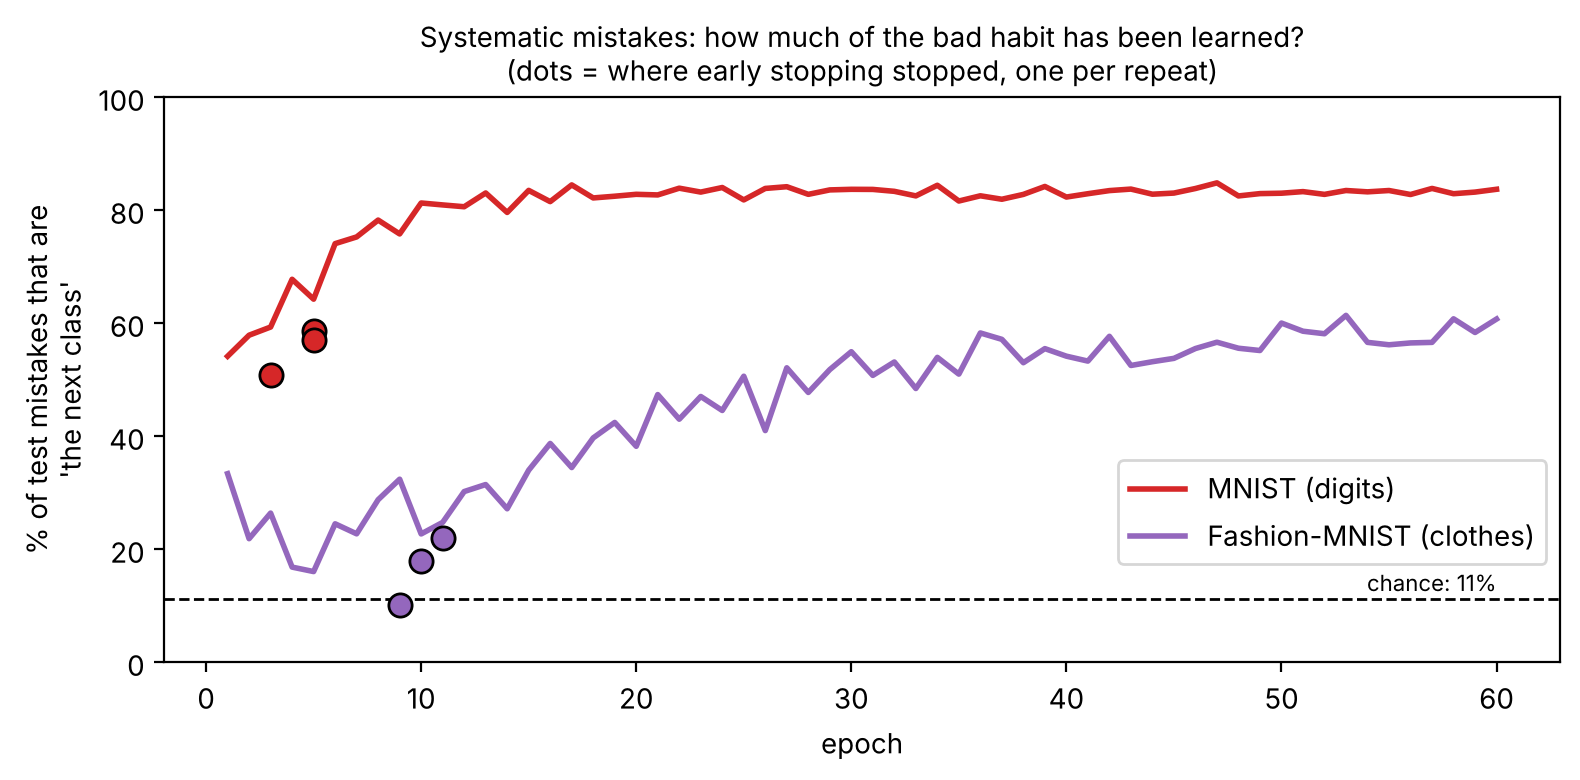

In [18]:
SHOW2 = min(60, FULL_EPOCHS)
fig, ax = plt.subplots(figsize=(8, 4))
for name, runs, d, colour in [("MNIST (digits)", full["systematic"], per_run, "C3"),
                              ("Fashion-MNIST (clothes)", fashion["systematic"], f_run, "C4")]:
    curve = 100 * mean_curve(runs, "test_err_next")[:SHOW2]
    ax.plot(np.arange(1, SHOW2 + 1), curve, color=colour, lw=2, label=name)
    stops = d[d["condition"] == "systematic"]
    ax.scatter(stops["stop_epoch"], 100 * stops["next_share"], s=70, color=colour, edgecolor="k", zorder=3)
ax.axhline(100 / 9, color="k", ls="--", lw=1)
ax.text(SHOW2, 100 / 9 + 1.5, "chance: 11%", ha="right", fontsize=8)
ax.set_ylim(0, 100)
ax.set_xlabel("epoch")
ax.set_ylabel("% of test mistakes that are\n'the next class'")
ax.set_title("Systematic mistakes: how much of the bad habit has been learned?\n(dots = where early stopping stopped, one per repeat)", fontsize=10)
ax.legend(loc="lower right", bbox_to_anchor=(1, 0.15))
fig.tight_layout()
save_fig(fig, "nb3_mnist_vs_fashion.png")
plt.show()

In both cases the line ends high, so with enough time the network **does** learn the bad habit, and the difference is **when**.

- **MNIST (red).** The line is high from the first epochs, so when early stopping stops (red dots), the network already has part of the habit.
- **Fashion-MNIST (purple).** The line stays low for longer and goes up later, so early stopping stops (purple dots) **before** most of the rise.

> **Key point.** Whether early stopping protects against systematic mistakes depends on **when** the network learns the bad habit: before the stopping point or after it. On MNIST it came early; on Fashion-MNIST, at the learning rates we chose, it came late.

Two limits of this explanation:

- We do **not** know why the timing is different for the two sets of pictures, because we did not test it.
- The timing also depends on the learning rate. Each kind of labels got its own learning rate, and for systematic mistakes that was the largest one we tried. NB2 (section 8.5) repeats the comparison with both kinds of labels at the same learning rate: at the two smaller learning rates Fashion-MNIST shows a clear gap, like MNIST, and the gap closes only at the two larger ones. So we cannot say how much of the difference between the two sets of pictures comes from the pictures and how much from the learning rate.

## 5. Why does this happen?

The two bar charts in section 2 explain most of it, if we think of training as a **tug of war** in which every training picture of a 3 pulls the network towards its own label.

**Random mistakes: people pulling in nine different directions.**
Take 100 pictures of a 3: 70 pull towards "3", and the other 30 pull towards nine different digits, about 3 each. Pulls in different directions mostly cancel each other, so the 70 win easily and the network learns "this shape is a 3". The only way to fit the 30 odd ones is to learn them by heart, one at a time, which is slow and therefore happens late, so early stopping can cut it off.

**Systematic mistakes: a team pulling in one direction.**
Now 70 pull towards "3" and 30 pull **together** towards "4". The 70 still win, but the 30 do not cancel each other, and their pull adds up just like the pull of the correct labels. As a result, "a 3 is sometimes a 4" works like a second, weaker rule, and the network starts to learn it right away.

Researchers call this idea **coherent gradients** (Chatterjee, 2020): examples that push the network the same way help each other, while examples that push in different ways do not.

**So what can early stopping do?** It can separate things that are learned at *different times*, but it cannot separate two things that are learned *at the same time*.

**One more check.** Early stopping might simply have stopped at the wrong moment, so the next cell compares the test score at the stopping point with the best test score of any epoch.

In [19]:
for c in ["random", "systematic"]:
    d = per_run[per_run["condition"] == c]
    missed = 100 * (d["acc_best"] - d["acc_stop"])
    print(f"{NAMES[c]:24s}: score at the stopping point is below the best possible score by "
          f"{[round(float(v), 1) for v in missed]} points (one value per repeat)")

30% random mistakes     : score at the stopping point is below the best possible score by [0.0, 0.0, 0.0] points (one value per repeat)
30% systematic mistakes : score at the stopping point is below the best possible score by [0.0, 0.0, 0.0] points (one value per repeat)


The numbers are zero or very close to zero, so early stopping found the best epoch, or almost the best. It did not stop at the wrong time; **the best moment was simply lower.**

> **How sure are we?** Our results fit the "one team pulling together" story, but we did not test that story directly, so it is why we expected this result and not something we proved.

## 6. Check yourself

Try each question before opening its answer.

**Q1.** A network is trained on labels with 30% random mistakes. At the end, it agrees with 100% of its training labels. Is that good?

<details><summary>Answer</summary>

No, because 30% of those labels are wrong, so agreeing with all of them means the network learned every mistake by heart, and by then its score on new pictures has gone down.

</details>

**Q2.** Early stopping uses the validation pictures to choose when to stop. But our validation labels also have 30% mistakes. Why does it still work with random mistakes?

<details><summary>Answer</summary>

Random wrong labels make the validation score lower at every epoch, by about the same amount, so all the scores are too low but the best epoch is still the best, and we only need to know which epoch is best, not the exact score.

</details>

**Q3.** What if 60% of the labels had the systematic mistake, not 30%?

<details><summary>Answer</summary>

Then most pictures of a 3 say "4" and the wrong label wins the tug of war, so the network should learn the wrong rule first and early stopping should not help. **We did not run this**, so it is a guess from the idea in section 5 and not a result.

</details>

**Q4.** A friend says: "Systematic mistakes are worse only because they make the task harder." Which result says no?

<details><summary>Answer</summary>

The chart "where do the mistakes go?" in section 4. If the task were only harder, the mistakes would be spread over all digits, but more than half of them are exactly "the next digit", which is far more than chance and shows that the network learned the bad habit.

</details>

**Try it yourself (if you like).** In the setup cell, change `DEMO_N_TRAIN` to 4000 or `DEMO_LR` to `3e-4`, run section 3 again, and see whether the solid and dashed lines still cross, and whether they cross earlier or later.

## 7. What we can say, and what we cannot

**We can say.** On MNIST, with our network and 30% wrong labels, early stopping protects less against systematic mistakes than against random mistakes: it ends lower and undoes a smaller share of the damage. This held at every learning rate we tried (NB2, section 7.4), and the mistakes that are left are often the ones the wrong labels taught.

**We cannot say.**

- **That it is always true.** On Fashion-MNIST the gap was too small to be sure at the learning rates we chose, although it was clear at smaller ones.
- **How much comes from the pictures and how much from the learning rate.** The gap shrinks as the learning rate grows, so the difference between MNIST and Fashion-MNIST could come from either.
- **Anything about other set-ups.** We used one kind of network, 10,000 training pictures and 30% wrong labels, and we left out the usual tricks (weight decay, dropout, data augmentation) on purpose.
- **Anything about other bad habits.** Our habit was "the next digit", while a real person more often mixes up things that look alike, such as 4 and 9.
- **Anything about small gaps.** Three repeats are enough to see the gap on MNIST, but they are not enough to rule out a small gap on Fashion-MNIST.
- **Anything about other ways to stop.** We trained all 200 epochs and then picked the best one, and a rule that stops *during* training could stop at a different epoch.

## The whole notebook in five sentences

1. With random wrong labels, the network learns the real patterns before memorising the mistakes, so early stopping can reduce their impact.
2. With systematic wrong labels, the mistakes follow a consistent pattern, allowing the network to learn the wrong rule much earlier.
3. On MNIST, early stopping still added many points with systematic mistakes, but it ended lower than with random ones and undid a smaller share of the damage, and more than half of the remaining mistakes matched the taught error.
4. On Fashion-MNIST, at the learning rates we chose, the network learned the wrong pattern later, mostly after the stopping point, and the gap nearly disappeared; at smaller learning rates the gap was clear.
5. Therefore, early stopping is less effective against systematic mistakes when the network learns the wrong rule before the stopping point, and when that happens depends on the dataset and on the learning rate.

## References

- Arpit et al. (2017). A Closer Look at Memorization in Deep Networks. Proceedings of the 34th International Conference on Machine Learning (ICML), PMLR 70.
- Han et al. (2018). Co-teaching: Robust Training of Deep Neural Networks with Extremely Noisy Labels. Advances in Neural Information Processing Systems 31 (NeurIPS).
- Chatterjee (2020). Coherent Gradients: An Approach to Understanding Generalization in Gradient Descent-based Optimization. International Conference on Learning Representations (ICLR).
- Prince (2023). Understanding Deep Learning. MIT Press, §9.3.1 (early stopping).